# Capstone · Stage 1 — Market insight for Kestrel Bay Capital

*Skill from Part 1: turn a year of market data into trends, portfolio implications and risk.*

**Fictional client and synthetic data.** Kestrel Bay Capital and its market are generated by `src/generate_data.py`
(fixed seed). The data are committed in `data/`, so this notebook runs as is.

1. Load the client profile and 52 weeks of market data
2. Sector statistics, including sensitivity to interest rates → `figures/s1_table_sectors.tex`
3. Figure 1 — a year in three panels: sector performance, VIX, policy rate → `figures/s1_fig_market.pdf`
4. The client's portfolio: return, volatility, drawdown against its 10% limit, risk contribution → `figures/s1_table_portfolio.tex`, `figures/s1_fig_risk.pdf`
5. Key findings that feed Stage 2

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA, FIG = Path("data"), Path("figures"); FIG.mkdir(exist_ok=True)
profile = json.loads((DATA / "client_profile.json").read_text())
m = pd.read_csv(DATA / "market_weekly.csv")
SECTORS = ["Technology", "Healthcare", "Financials", "Energy", "Renewable Energy", "Real Estate"]
R = m[[f"{s} (%)" for s in SECTORS]].set_axis(SECTORS, axis=1)

# Categorical palette in fixed order (validated: lightness, chroma, CVD separation, normal-vision floor).
# Three slots are below 3:1 contrast, so every chart is direct-labelled and backed by a table.
COL = dict(zip(SECTORS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
INK, MUTED, NAVY = "#222222", "#666666", "#0A2A6B"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#BBBBBB", "xtick.color": MUTED, "ytick.color": MUTED})

def tex(v, fmt="{:.1f}", sign=False):
    s = (("{:+" + fmt[2:]) if sign else fmt).format(v)
    return s.replace("-", r"\textminus{}")

print(profile["name"], "-", profile["type"], f"- AUM ${profile['aum_usd']/1e6:.0f}m")
pd.Series(profile["allocation_pct"], name="Allocation (%)").to_frame().T

Kestrel Bay Capital - Mid-sized multi-family office - AUM $250m


,Technology,Healthcare,Financials,Energy,Renewable Energy,Real Estate,Cash
Allocation (%),35,15,10,0,15,10,15


## 2. Sector statistics

In [2]:
def max_drawdown(r_pct):
    idx = (1 + r_pct / 100).cumprod()
    return 100 * (idx / idx.cummax() - 1).min()

d_rate_steps = m["policy_rate_pct"].diff().fillna(0) / 0.25          # rate change in 25 bp steps
X = np.column_stack([np.ones(52), m["market_return_pct"], d_rate_steps])
rate_beta = {s: np.linalg.lstsq(X, R[s], rcond=None)[0][2] for s in SECTORS}   # % per 25 bp, market held fixed

stats = pd.DataFrame({
    "Return 52w (%)": ((1 + R / 100).prod() - 1) * 100,
    "Volatility, annual (%)": R.std() * np.sqrt(52),
    "Max drawdown (%)": R.apply(max_drawdown),
    "Return / volatility": (R.mean() * 52) / (R.std() * np.sqrt(52)),
    "Corr. with VIX change": R.corrwith(m["vix"].diff()),
    "Move per +25 bp (%)": pd.Series(rate_beta),
})
stats.round(2)

,Return 52w (%),"Volatility, annual (%)",Max drawdown (%),Return / volatility,Corr. with VIX change,Move per +25 bp (%)
Technology,22.73,14.30,-4.70,1.50,-0.50,0.07
Healthcare,8.90,8.69,-7.80,1.02,-0.31,0.23
Financials,9.85,12.63,-9.43,0.81,-0.37,0.90
Energy,24.98,16.02,-10.68,1.47,-0.02,0.38
Renewable Energy,33.62,18.65,-6.46,1.65,-0.22,-0.23
Real Estate,4.57,12.43,-13.02,0.42,-0.50,-0.46


**Caution on the rate column.** The policy rate moved in only 5 of 52 weeks, so each "move per +25 bp" estimate rests on
5 observations and is noisy. The generator *does* build Technology and Renewable Energy to fall when rates rise, yet the
estimate for Technology comes out near zero, because the noise in those 5 weeks swamps the effect. The lesson for the client: one year of
data cannot measure rate sensitivity reliably; Stage 2 tests it with explicit rate scenarios instead.

In [3]:
lines = [r"\begin{tabular}{@{}lrrrrrr@{}}", r"\toprule",
         r"Sector & Return & Volatility & Max & Return / & Corr.\ with & Move per \\",
         r"       & 52 weeks & (annual) & drawdown & volatility & VIX change & +25 bp \\", r"\midrule"]
for s, r in stats.iterrows():
    lines.append(f"{s} & {tex(r.iloc[0], sign=True)}\\% & {tex(r.iloc[1])}\\% & {tex(r.iloc[2])}\\% & "
                 f"{tex(r.iloc[3], '{:.2f}')} & {tex(r.iloc[4], '{:.2f}')} & {tex(r.iloc[5], '{:.2f}', sign=True)}\\% \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(FIG / "s1_table_sectors.tex").write_text("\n".join(lines)); print("\n".join(lines))

\begin{tabular}{@{}lrrrrrr@{}}
\toprule
Sector & Return & Volatility & Max & Return / & Corr.\ with & Move per \\
       & 52 weeks & (annual) & drawdown & volatility & VIX change & +25 bp \\
\midrule
Technology & +22.7\% & 14.3\% & \textminus{}4.7\% & 1.50 & \textminus{}0.50 & +0.07\% \\
Healthcare & +8.9\% & 8.7\% & \textminus{}7.8\% & 1.02 & \textminus{}0.31 & +0.23\% \\
Financials & +9.8\% & 12.6\% & \textminus{}9.4\% & 0.81 & \textminus{}0.37 & +0.90\% \\
Energy & +25.0\% & 16.0\% & \textminus{}10.7\% & 1.47 & \textminus{}0.02 & +0.38\% \\
Renewable Energy & +33.6\% & 18.6\% & \textminus{}6.5\% & 1.65 & \textminus{}0.22 & \textminus{}0.23\% \\
Real Estate & +4.6\% & 12.4\% & \textminus{}13.0\% & 0.42 & \textminus{}0.50 & \textminus{}0.46\% \\
\bottomrule
\end{tabular}


## 3. Figure 1 — the year in three panels

One measure per panel (no dual axis), sharing the same weeks. Dotted lines mark the events.

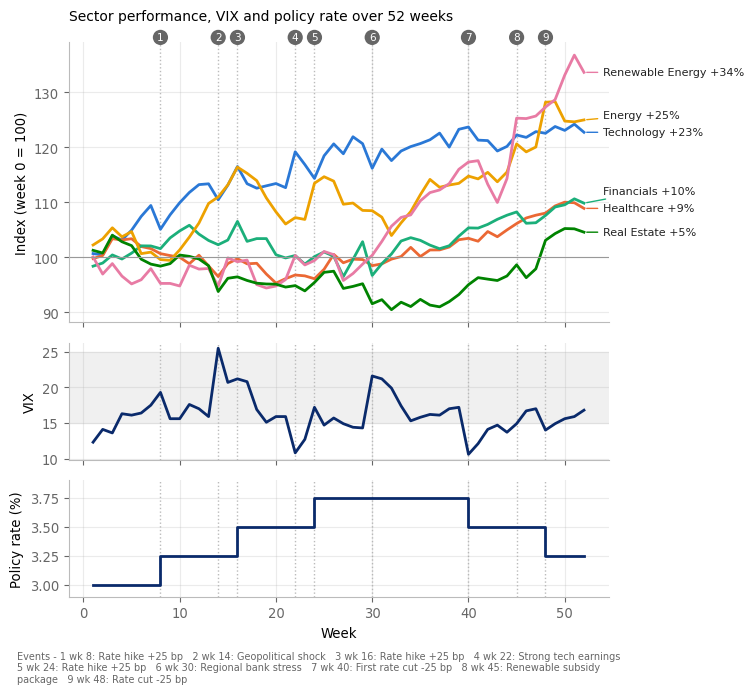

In [4]:
idx = 100 * (1 + R / 100).cumprod()
fig, axes = plt.subplots(3, 1, figsize=(8, 7.2), sharex=True, gridspec_kw={"height_ratios": [2.4, 1, 1]})
ax = axes[0]
for s in SECTORS:
    ax.plot(m["week"], idx[s], color=COL[s], lw=2)
ends = idx.iloc[-1].sort_values()
y_lab = ends.values.copy()
for i in range(1, len(y_lab)):                  # spread end labels so they never overlap
    y_lab[i] = max(y_lab[i], y_lab[i-1] + 3.2)
for (s, v), yl in zip(ends.items(), y_lab):
    ax.annotate(f"{s} {v-100:+.0f}%", (52, v), xytext=(54, yl), textcoords="data",
                fontsize=8, color=INK, va="center", annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=COL[s], lw=1))
ax.axhline(100, color="#999999", lw=0.8)
ax.set_ylabel("Index (week 0 = 100)"); ax.grid(alpha=0.25)
ax.set_title("Sector performance, VIX and policy rate over 52 weeks", loc="left", fontsize=10, pad=16)

axes[1].plot(m["week"], m["vix"], color=NAVY, lw=2)
axes[1].axhspan(15, 25, color="0.94", zorder=0)
axes[1].set_ylabel("VIX"); axes[1].grid(alpha=0.25)
axes[2].step(m["week"], m["policy_rate_pct"], where="post", color=NAVY, lw=2)
axes[2].set_ylabel("Policy rate (%)"); axes[2].set_xlabel("Week"); axes[2].grid(alpha=0.25)
axes[2].set_ylim(2.9, 3.9)

ev = m.loc[m["event"].notna(), ["week", "event"]]
for _, e in ev.iterrows():
    for a in axes:
        a.axvline(e["week"], color="#BBBBBB", ls=":", lw=1, zorder=0)
top = axes[0].get_ylim()[1]
for k, (_, e) in enumerate(ev.iterrows(), start=1):          # numbered markers, key below the chart
    axes[0].annotate(str(k), (e["week"], top), ha="center", va="bottom", fontsize=7.5, color="white",
                     bbox=dict(boxstyle="circle,pad=0.25", fc=MUTED, ec="none"), annotation_clip=False)
import textwrap
key = "   ".join(f"{k} wk {e['week']}: {e['event']}" for k, (_, e) in enumerate(ev.iterrows(), start=1))
fig.text(0.06, 0.035, chr(10).join(textwrap.wrap("Events - " + key, 125)), fontsize=7, color=MUTED, va="top")
fig.subplots_adjust(right=0.80, hspace=0.12)
fig.savefig(FIG / "s1_fig_market.pdf", bbox_inches="tight"); plt.show()

## 4. The client's portfolio

Cash earns the policy rate (weekly: rate / 52). Annual figures scale weekly ones by 52 (return) and √52 (volatility).

In [5]:
w = pd.Series(profile["allocation_pct"], dtype=float) / 100
port = (R[SECTORS] * w[SECTORS]).sum(axis=1) + w["Cash"] * m["policy_rate_pct"] / 52
cov = R[SECTORS].cov().values
wv = w[SECTORS].values
rc = wv * (cov @ wv) / (wv @ cov @ wv)                     # share of portfolio variance
risk = pd.DataFrame({"Capital (%)": 100 * w[SECTORS], "Share of risk (%)": 100 * rc}, index=SECTORS)

p_stats = {
    "Return 52w (%)": ((1 + port / 100).prod() - 1) * 100,
    "Volatility, annual (%)": port.std() * np.sqrt(52),
    "Max drawdown (%)": max_drawdown(port),
    "Return / volatility": port.mean() * 52 / (port.std() * np.sqrt(52)),
    "Move per +25 bp (%)": float((w[SECTORS] * pd.Series(rate_beta)).sum()),
}
target, dd_limit = 6.0, -10.0
print(f"Return target {target}% -> {'met' if p_stats['Return 52w (%)'] >= target else 'missed'}; "
      f"drawdown limit {dd_limit}% -> {'respected' if p_stats['Max drawdown (%)'] > dd_limit else 'breached'}")
display(pd.Series(p_stats).round(2).to_frame("Kestrel Bay portfolio"))
risk.round(1)

Return target 6.0% -> met; drawdown limit -10.0% -> respected


,Kestrel Bay portfolio
Return 52w (%),16.34
"Volatility, annual (%)",8.82
Max drawdown (%),-2.94
Return / volatility,1.76
Move per +25 bp (%),0.07


,Capital (%),Share of risk (%)
Technology,35.0,50.9
Healthcare,15.0,9.0
Financials,10.0,8.9
Energy,0.0,0.0
Renewable Energy,15.0,22.3
Real Estate,10.0,9.0


In [6]:
rows = [("Return over 52 weeks", tex(p_stats["Return 52w (%)"], sign=True) + r"\%", "target $\\geq$ 6\\%"),
        ("Volatility (annual)", tex(p_stats["Volatility, annual (%)"]) + r"\%", ""),
        ("Maximum drawdown", tex(p_stats["Max drawdown (%)"]) + r"\%", "limit 10\\%"),
        ("Return / volatility", tex(p_stats["Return / volatility"], "{:.2f}"), ""),
        ("Portfolio move per +25 bp", tex(p_stats["Move per +25 bp (%)"], "{:.2f}", sign=True) + r"\%", ""),
        ("Technology: capital vs.\\ risk", f"{risk.loc['Technology','Capital (%)']:.0f}\\% vs.\\ {risk.loc['Technology','Share of risk (%)']:.0f}\\%", "")]
lines = [r"\begin{tabular}{@{}lrl@{}}", r"\toprule", r"\textbf{Metric} & \textbf{Value} & \textbf{Client rule} \\", r"\midrule"]
lines += [f"{a} & {b} & {c} \\\\" for a, b, c in rows] + [r"\bottomrule", r"\end{tabular}"]
(FIG / "s1_table_portfolio.tex").write_text("\n".join(lines)); print("\n".join(lines))

\begin{tabular}{@{}lrl@{}}
\toprule
\textbf{Metric} & \textbf{Value} & \textbf{Client rule} \\
\midrule
Return over 52 weeks & +16.3\% & target $\geq$ 6\% \\
Volatility (annual) & 8.8\% &  \\
Maximum drawdown & \textminus{}2.9\% & limit 10\% \\
Return / volatility & 1.76 &  \\
Portfolio move per +25 bp & +0.07\% &  \\
Technology: capital vs.\ risk & 35\% vs.\ 51\% &  \\
\bottomrule
\end{tabular}


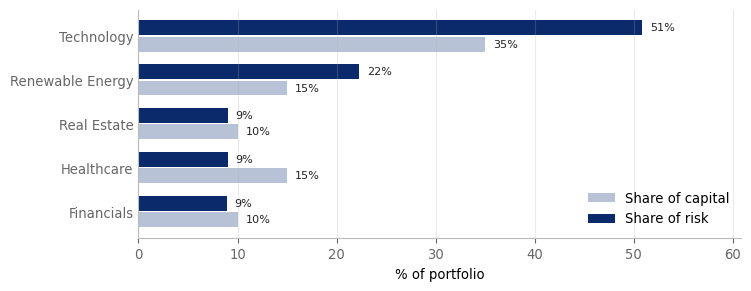

In [7]:
held = risk[risk["Capital (%)"] > 0].sort_values("Share of risk (%)")
fig, ax = plt.subplots(figsize=(7.6, 3.0))
y = np.arange(len(held)); h = 0.38
ax.barh(y - h/2, held["Capital (%)"], height=h - 0.04, color="#B8C2D6", label="Share of capital")
ax.barh(y + h/2, held["Share of risk (%)"], height=h - 0.04, color=NAVY, label="Share of risk")
for i, (c, r) in enumerate(zip(held["Capital (%)"], held["Share of risk (%)"])):
    ax.text(c + 0.8, i - h/2, f"{c:.0f}%", va="center", fontsize=8, color=INK)
    ax.text(r + 0.8, i + h/2, f"{r:.0f}%", va="center", fontsize=8, color=INK)
ax.set_yticks(y, held.index); ax.tick_params(axis="y", length=0)
ax.set_xlabel("% of portfolio"); ax.set_xlim(0, max(held.max()) + 10); ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "s1_fig_risk.pdf", bbox_inches="tight"); plt.show()

## 5. Key findings (computed, not typed)

In [8]:
best = stats["Return / volatility"].idxmax()
most_rate = stats["Move per +25 bp (%)"].idxmin()
findings = [
    f"Portfolio return {p_stats['Return 52w (%)']:+.1f}% vs a 6% target; max drawdown {p_stats['Max drawdown (%)']:.1f}% vs a 10% limit.",
    f"Technology is {risk.loc['Technology','Capital (%)']:.0f}% of capital but {risk.loc['Technology','Share of risk (%)']:.0f}% of risk.",
    f"Most rate-sensitive sector: {most_rate} ({stats.loc[most_rate,'Move per +25 bp (%)']:+.2f}% per +25 bp, market held fixed).",
    f"Best return per unit of volatility: {best} ({stats.loc[best,'Return / volatility']:.2f}).",
    f"The client holds no Energy, which rose {stats.loc['Energy','Return 52w (%)']:+.0f}% and moves with rates rather than against them.",
]
for f in findings: print("-", f)
(FIG / "s1_findings.txt").write_text("\n".join(findings))

- Portfolio return +16.3% vs a 6% target; max drawdown -2.9% vs a 10% limit.
- Technology is 35% of capital but 51% of risk.
- Most rate-sensitive sector: Real Estate (-0.46% per +25 bp, market held fixed).
- Best return per unit of volatility: Renewable Energy (1.65).
- The client holds no Energy, which rose +25% and moves with rates rather than against them.


352